# CityFlow — Real-Time Traffic Intelligence

### Prototype de traitement de flux avec Apache Spark Structured Streaming

**Module :** Écosystème Big Data 2 — Pr. Soukaina Gouraguine
**Année universitaire :** 2026–2027
**Projet 3 :** City Flow — Real-Time Traffic Intelligence

**Réalisé par :** Mazine CHATER · Yahya BAID · Wenn Bouka DIEUMERCI

---

Ce notebook constitue le livrable **L2 (code source)** du projet. Il déroule pas à pas la
démarche du cahier des charges : compréhension du traitement de flux, modèle
source → transformation → sink, micro-batch et table infinie, fenêtres temporelles et
watermarking, puis exploitation des résultats.

> **Scénario métier.** Une régie de mobilité urbaine collecte en continu les passages de
> véhicules à des capteurs répartis dans huit zones de Casablanca. Elle veut connaître, en
> quasi temps réel, le volume de trafic et l'état de congestion par zone et par fenêtre de
> 10 minutes.

## Sommaire

1. [Contexte, problématique et objectifs](#1-contexte-problématique-et-objectifs)
2. [Traitement batch vs traitement de flux](#2-traitement-batch-vs-traitement-de-flux)
3. [Le modèle source → transformation → sink](#3-le-modèle-source--transformation--sink)
4. [Table infinie et micro-batch](#4-table-infinie-et-micro-batch)
5. [Fenêtres temporelles et watermarking](#5-fenêtres-temporelles-et-watermarking)
6. [Implémentation du pipeline](#6-implémentation-du-pipeline)
7. [Résultats et interprétation](#7-résultats-et-interprétation)
8. [Expérience contrôlée : données tardives et watermark](#8-expérience-contrôlée--données-tardives-et-watermark)
9. [Comparaison batch / streaming](#9-comparaison-batch--streaming)
10. [Limites et perspectives](#10-limites-et-perspectives)

## 1. Contexte, problématique et objectifs

### 1.1 Contexte

Les systèmes de mobilité (boucles inductives, caméras, capteurs connectés, données GPS)
produisent **en continu** des événements : passage d'un véhicule, mesure de vitesse,
changement d'état du feu, etc. Ces événements arrivent dans le désordre, parfois en retard,
et leur volume dépasse rapidement ce qu'un tableur ou un script pandas peut traiter.

### 1.2 Problématique métier

> Comment calculer en continu, et de façon fiable, des indicateurs de trafic par zone et par
> fenêtre temporelle, à partir d'un flux d'événements qui arrive progressivement et dont
> certains événements sont retardés ?

Questions auxquelles le prototype doit répondre :

- Quelles zones concentrent le plus de passages de véhicules ?
- Quelles fenêtres de 10 minutes sont les plus congestionnées ?
- Comment la vitesse moyenne évolue-t-elle entre 07:00 et 09:00 ?
- Que devient un événement qui arrive après la fermeture de sa fenêtre ?
- Comment reprendre le traitement après un arrêt sans perdre ni dupliquer les données ?

### 1.3 Objectifs du prototype

1. Lire un flux de fichiers JSON ajoutés progressivement.
2. Typer, nettoyer et enrichir les événements (jointure avec un référentiel de zones).
3. Agréger par zone et par fenêtre temporelle de 10 minutes.
4. Gérer les événements tardifs avec un watermark de 10 minutes.
5. Écrire les résultats dans des sinks durables (Parquet) et interrogeables (mémoire/SQL).
6. Mesurer et interpréter le comportement du pipeline (latence par micro-batch, données ignorées).

## 2. Traitement batch vs traitement de flux

| Critère | Traitement batch | Traitement de flux |
|---|---|---|
| Entrée | Jeu de données **fini**, borné, déjà présent | Flux **infini**, arrivée continue |
| Déclenchement | Planifié (cron, orchestration) | Continu, au fil de l'eau |
| Latence | Minutes à heures | Secondes à minutes |
| Granularité | Tout le dataset à chaque exécution | Micro-batchs (ou enregistrement par enregistrement) |
| Gestion du temps | Temps de traitement uniquement | **Temps de l'événement** + temps de traitement |
| Panne | Relance du job complet | Reprise depuis un **checkpoint** |
| Usage typique | Reporting, historisation, entraînement | Alerting, supervision, tableaux de bord temps réel |

**Point clé.** Un traitement batch sur les mêmes données produira *in fine* des agrégats
similaires, mais il ne pourra commencer qu'une fois tous les fichiers disponibles. Le
streaming produit des résultats **au fur et à mesure**, au prix d'une gestion explicite du
temps et des données en retard.

Dans ce projet, les deux modes sont implémentés sur le même jeu de données afin de comparer
les résultats et le comportement (section 9).

## 3. Le modèle source → transformation → sink

Structured Streaming repose sur trois briques :

| Brique | Rôle | Dans CityFlow |
|---|---|---|
| **Source** | D'où viennent les données ? | Répertoire de fichiers JSON, lus avec un schéma explicite et `maxFilesPerTrigger=1` |
| **Transformation** | Que fait-on des données ? | Nettoyage, typage, enrichissement (zones), fenêtrage, agrégations |
| **Sink** | Où vont les résultats ? | Console (debug), mémoire (SQL), Parquet (durable, Bronze/Gold) |

Le moteur est **paresseux** : aucune donnée n'est lue tant qu'une action de sortie
(`writeStream.start()`) n'est pas déclenchée. Chaque sink matérialise un résultat
différent du même flux.

In [1]:
import json
import shutil
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from pyspark.sql import functions as F

# --- Localisation robuste de la racine du projet ---------------------------
ROOT = Path.cwd()
while ROOT != ROOT.parent and not (ROOT / "L3_Dataset").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "L2_Code" / "scripts"))

from cityflow_lib import (
    WATERMARK_DELAY, WINDOW_DURATION,
    clean_events, enrich_with_zones, read_event_stream, read_events_batch,
    read_zones, windowed_zone_stats, windowed_global_stats,
)
from spark_session import build_spark

# --- Chemins ---------------------------------------------------------------
STREAM_DIR = ROOT / "L3_Dataset" / "data" / "stream"
ZONES_CSV = ROOT / "L3_Dataset" / "data" / "reference" / "zones.csv"
METADATA = ROOT / "L3_Dataset" / "data" / "metadata.json"
RUNTIME = ROOT / "L2_Code" / "notebooks" / "_runtime"
OUTPUT = ROOT / "output"

# --- Session Spark ---------------------------------------------------------
spark = build_spark("CityFlow-Notebook")
spark.sparkContext.setLogLevel("ERROR")

print("Spark        :", spark.version)
print("Racine       :", ROOT)
print("Source       :", STREAM_DIR)
print("Watermark    :", WATERMARK_DELAY)
print("Fenêtre      :", WINDOW_DURATION)

meta = json.loads(METADATA.read_text(encoding="utf-8"))
print(f"Jeu de données : {meta['total_events']:,} événements, "
      f"{meta['files']} fichiers, {meta['late_events']:,} en retard")

Spark        : 3.5.3
Racine       : C:\Users\mazin\OneDrive\デスクトップ\Projets 5eme année\Projet Big Data\Projet3_CityFlow_RealTime_Traffic
Source       : C:\Users\mazin\OneDrive\デスクトップ\Projets 5eme année\Projet Big Data\Projet3_CityFlow_RealTime_Traffic\L3_Dataset\data\stream
Watermark    : 10 minutes
Fenêtre      : 10 minutes
Jeu de données : 52,846 événements, 12 fichiers, 2,194 en retard


### 3.1 Le schéma explicite : première brique de fiabilité

En streaming, **inférer le schéma** à chaque lecture est coûteux et instable. On impose donc
un schéma : les colonnes sont typées dès l'ingestion, et une ligne JSON invalide devient une
ligne de valeurs nulles (mode `PERMISSIVE`) que le nettoyage élimine.

Le schéma est défini dans `cityflow_lib.EVENT_SCHEMA` :

| Colonne | Type | Description |
|---|---|---|
| `event_id` | string | Identifiant unique du passage |
| `event_time` | string → timestamp | Horodatage de l'événement (UTC, ISO-8601) |
| `zone_id` / `zone_name` | string | Zone géographique |
| `sensor_id` / `lane` | string / int | Capteur et voie |
| `vehicle_type` | string | car, taxi, moto, bus, truck |
| `speed_kmh` | double | Vitesse instantanée mesurée |

## 4. Table infinie et micro-batch

### 4.1 La table infinie

On peut voir un flux comme une **table infinie** à laquelle de nouvelles lignes s'ajoutent en
permanence. Une requête de streaming n'est pas exécutée « sur tout le flux » : elle est
recalculée de façon **incrémentale** à chaque micro-batch, en ne traitant que les nouvelles
lignes.

```
Temps réel ─────────────────────────────────────────────────────────────►
Fichier 1   Fichier 2   Fichier 3   Fichier 4 ...
   │           │           │           │
   ▼           ▼           ▼           ▼
[Batch 0]   [Batch 1]   [Batch 2]   [Batch 3]   ← micro-batchs
   │           │           │           │
   └───────────┴───────────┴───────────┴──► état incrémental + sinks
```

### 4.2 Micro-batch

Spark Structured Streaming découpe le flux en **micro-batchs**. Chaque micro-batch :

1. lit les nouvelles données de la source ;
2. met à jour l'**état** (State Store) pour les agrégations stateful ;
3. écrit le résultat dans le sink ;
4. sauvegarde sa progression dans le **checkpoint**.

Dans notre démonstration, `maxFilesPerTrigger=1` force **un fichier = un micro-batch**, ce
qui rend l'évolution des résultats observable. En production, la taille des micro-batchs est
pilotée par `maxFilesPerTrigger`, `maxBytesPerTrigger` ou un déclencheur temporel.

### 4.3 Les modes de sortie

| Mode | Comportement | Sink typique |
|---|---|---|
| `append` | N'écrit que les **nouvelles** lignes ; avec watermark, une fenêtre n'est écrite qu'une fois finalisée | Parquet, Delta |
| `update` | Réécrit les lignes **modifiées** depuis le dernier batch | Console, dashboard |
| `complete` | Réécrit **tout** le résultat à chaque batch | Table mémoire, petite agrégation |

Le choix du mode dépend de la sémantique voulue : un sink durable doit généralement utiliser
`append` pour éviter les doublons, tandis qu'un tableau de bord utilisera `update`.

## 5. Fenêtres temporelles et watermarking

### 5.1 Temps de l'événement vs temps de traitement

- **Temps de l'événement** (*event time*) : moment où le phénomène s'est produit (mesure du capteur).
- **Temps de traitement** (*processing time*) : moment où Spark reçoit et traite la donnée.

Un événement peut arriver en retard (panne réseau, buffer, synchronisation). Agréger sur le
temps de traitement donnerait des résultats instables. CityFlow agrège donc sur
`event_time`.

### 5.2 Fenêtre tumblante de 10 minutes

`window(event_time, "10 minutes")` découpe le temps en intervalles **disjoints** :
`[07:00, 07:10)`, `[07:10, 07:20)`, etc. Chaque événement appartient à exactement une
fenêtre, ce qui permet de réconcilier les volumes.

### 5.3 Watermark

Le watermark indique jusqu'où le système accepte encore des données en retard :

```python
events.withWatermark("event_time", "10 minutes")
```

- Spark mémorise l'état des fenêtres jusqu'à **10 minutes après le timestamp maximal vu**.
- Une fenêtre dont la fin est antérieure au watermark est **finalisée** puis retirée de l'état.
- Un événement qui arrive après la finalisation de sa fenêtre est **ignoré** (et compté dans
  la métrique `numRowsDroppedByWatermark`).

Sans watermark, l'état grossirait indéfiniment : le watermark borne la mémoire et permet de
supporter un flux infini.

> **Nuance importante observée en pratique.** Avec une fenêtre de 10 min et un watermark de
> 10 min, les événements qui arrivent dans le micro-batch même où la fenêtre se ferme peuvent
> encore être intégrés. La tolérance réelle dépend donc du déclenchement et de l'ordre
> d'arrivée des fichiers. C'est pourquoi le jeu de données contient des retards allant
> jusqu'à 45 minutes : ils permettent d'observer de vrais rejets.

## 6. Implémentation du pipeline

### 6.1 Lecture du flux

On lit le répertoire `L3_Dataset/data/stream` comme une source de fichiers JSON. Spark
détecte les nouveaux fichiers à chaque micro-batch.

In [2]:
raw = read_event_stream(spark, str(STREAM_DIR), max_files_per_trigger=1)
print("DataFrame streaming ?", raw.isStreaming)
raw.printSchema()
raw.explain("formatted")

DataFrame streaming ? True
root
 |-- event_id: string (nullable = true)
 |-- event_time: string (nullable = true)
 |-- zone_id: string (nullable = true)
 |-- zone_name: string (nullable = true)
 |-- sensor_id: string (nullable = true)
 |-- lane: integer (nullable = true)
 |-- vehicle_type: string (nullable = true)
 |-- speed_kmh: double (nullable = true)



== Physical Plan ==
StreamingRelation (1)


(1) StreamingRelation
Output [8]: [event_id#0, event_time#1, zone_id#2, zone_name#3, sensor_id#4, lane#5, vehicle_type#6, speed_kmh#7]
Arguments: FileSource[C:\Users\mazin\OneDrive\デスクトップ\Projets 5eme année\Projet Big Data\Projet3_CityFlow_RealTime_Traffic\L3_Dataset\data\stream], [event_id#0, event_time#1, zone_id#2, zone_name#3, sensor_id#4, lane#5, vehicle_type#6, speed_kmh#7]




Le plan logique fait apparaître `StreamingRelation` : la DataFrame est bien un flux, pas une
table statique. Le plan physique sera construit à chaque micro-batch par Catalyst.

### 6.2 Nettoyage et enrichissement (jointure stream-static)

- rejet des lignes corrompues (`event_id` ou `event_time` nul) ;
- validation du format de zone et de la plage de vitesse ;
- conversion de `event_time` en timestamp ;
- enrichissement avec le référentiel `zones.csv` : limite de vitesse, arrondissement, voies.

La table des zones est **statique et petite** : on la diffuse (`broadcast`) pour éviter un
shuffle à chaque micro-batch.

In [3]:
zones = read_zones(spark, str(ZONES_CSV))
zones.show(truncate=False)

events = enrich_with_zones(clean_events(raw, with_watermark=True), zones)
events.printSchema()

+-------+------------+-------------------------+---------------+-----+
|zone_id|zone_name   |district                 |speed_limit_kmh|lanes|
+-------+------------+-------------------------+---------------+-----+
|Z01    |Centre-Ville|Casablanca - Sidi Belyout|40             |4    |
|Z02    |Maarif      |Casablanca - Maarif      |40             |3    |
|Z03    |Ain Diab    |Casablanca - Ain Diab    |60             |3    |
|Z04    |Sidi Maarouf|Casablanca - Sidi Maarouf|60             |4    |
|Z05    |Hay Hassani |Casablanca - Hay Hassani |50             |3    |
|Z06    |Anfa        |Casablanca - Anfa        |40             |2    |
|Z07    |Bourgogne   |Casablanca - Anfa        |50             |3    |
|Z08    |Ain Sebaa   |Casablanca - Ain Sebaa   |60             |4    |
+-------+------------+-------------------------+---------------+-----+



root
 |-- zone_id: string (nullable = true)
 |-- event_id: string (nullable = true)
 |-- event_time: timestamp (nullable = true)
 |-- sensor_id: string (nullable = true)
 |-- lane: integer (nullable = true)
 |-- vehicle_type: string (nullable = true)
 |-- speed_kmh: double (nullable = true)
 |-- event_hour: timestamp (nullable = true)
 |-- speed_band: string (nullable = false)
 |-- zone_name: string (nullable = true)
 |-- district: string (nullable = true)
 |-- speed_limit_kmh: integer (nullable = true)
 |-- lanes: integer (nullable = true)
 |-- speed_ratio: double (nullable = true)
 |-- is_congested: integer (nullable = false)
 |-- congestion_level: string (nullable = false)



### 6.3 Agrégation par zone et par fenêtre

Indicateurs calculés :

- `vehicle_count` : nombre de passages (volume) ;
- `avg_speed_kmh`, `median_speed_kmh`, `p95_speed_kmh` : vitesse moyenne, médiane, 95e percentile ;
- `congestion_rate` : part des passages sous 60 % de la limite de vitesse ;
- `traffic_state` : état synthétique (Critique / Dense / Fluide / Libre) ;
- `active_sensors` : nombre de capteurs actifs (approximé pour rester compatible streaming).

In [4]:
aggregates = windowed_zone_stats(events, WINDOW_DURATION, WINDOW_DURATION)
aggregates.printSchema()

root
 |-- zone_id: string (nullable = true)
 |-- zone_name: string (nullable = true)
 |-- district: string (nullable = true)
 |-- speed_limit_kmh: integer (nullable = true)
 |-- vehicle_count: long (nullable = false)
 |-- avg_speed_kmh: double (nullable = true)
 |-- median_speed_kmh: double (nullable = true)
 |-- p95_speed_kmh: double (nullable = true)
 |-- min_speed_kmh: double (nullable = true)
 |-- max_speed_kmh: double (nullable = true)
 |-- congested_events: long (nullable = true)
 |-- active_sensors: long (nullable = false)
 |-- window_start: timestamp (nullable = true)
 |-- window_end: timestamp (nullable = true)
 |-- avg_speed_ratio: double (nullable = true)
 |-- congestion_rate: double (nullable = true)
 |-- traffic_state: string (nullable = false)
 |-- computed_at: timestamp (nullable = false)



### 6.4 Les sinks

Trois sinks sont illustrés dans ce notebook :

1. **Parquet Bronze** : événements nettoyés et enrichis, pour l'audit et le rejeu.
2. **Parquet Gold** : agrégats finalisés par zone et fenêtre, partitionnés par zone.
3. **Sink mémoire** : table SQL interrogeable, utilisée dans l'expérience de watermark.

Les deux sinks Parquet possèdent un **checkpoint** distinct : chaque requête peut reprendre
exactement là où elle s'est arrêtée, indépendamment des autres.

> Le code complet, réutilisable en ligne de commande, se trouve dans
> `L2_Code/scripts/cityflow_pipeline.py` (modes `available`, `live`, `batch`).

In [5]:
# Répertoire d'exécution propre pour le notebook (checkpoints + sorties)
if RUNTIME.exists():
    shutil.rmtree(RUNTIME)
BRONZE = RUNTIME / "bronze"
GOLD = RUNTIME / "gold"
CKPT = RUNTIME / "checkpoints"
for p in (BRONZE, GOLD, CKPT):
    p.mkdir(parents=True, exist_ok=True)

# --- Sink Bronze : événements typés et enrichis ----------------------------
q_bronze = (
    events.writeStream.format("parquet")
    .option("path", str(BRONZE))
    .option("checkpointLocation", str(CKPT / "bronze"))
    .outputMode("append")
    .queryName("nb_bronze")
    .trigger(availableNow=True)
    .start()
)
q_bronze.awaitTermination()
print("Bronze :", spark.read.parquet(str(BRONZE)).count(), "événements écrits")

Bronze : 52630 événements écrits


Le sink Gold utilise `foreachBatch` pour deux raisons pédagogiques :

- ajouter le **numéro de micro-batch** aux lignes écrites, afin de tracer leur émission ;
- journaliser des métriques par lot (lignes écrites, latence, watermark).

En `outputMode("append")`, une fenêtre n'est écrite **qu'une seule fois**, après que le
watermark l'a dépassée.

In [6]:
batch_log = []

def write_gold(batch_df, batch_id):
    started = time.perf_counter()
    rows = batch_df.count()
    if rows:
        (batch_df.withColumn("batch_id", F.lit(batch_id))
         .write.mode("append").partitionBy("zone_id").parquet(str(GOLD)))
    batch_log.append({
        "batch_id": batch_id,
        "rows_written": rows,
        "duration_ms": round((time.perf_counter() - started) * 1000),
    })

q_gold = (
    aggregates.writeStream.foreachBatch(write_gold)
    .option("checkpointLocation", str(CKPT / "gold"))
    .outputMode("append")
    .queryName("nb_gold")
    .trigger(availableNow=True)
    .start()
)
q_gold.awaitTermination()

progress = pd.DataFrame([
    {
        "batch_id": p["batchId"],
        "input_rows": p["numInputRows"],
        "trigger_ms": p["durationMs"]["triggerExecution"],
        "watermark": (p.get("eventTime") or {}).get("watermark"),
        "dropped_by_watermark": sum(
            op.get("numRowsDroppedByWatermark", 0) for op in (p.get("stateOperators") or [])
        ),
    }
    for p in q_gold.recentProgress
])
progress

,batch_id,input_rows,trigger_ms,watermark,dropped_by_watermark
0,0,4365,5764,1970-01-01T00:00:00.000Z,0
1,1,4310,2325,2026-11-02T06:59:59.989Z,0
2,2,4511,2711,2026-11-02T07:09:59.899Z,0
3,3,4332,4756,2026-11-02T07:19:59.907Z,0
4,4,4443,3551,2026-11-02T07:29:59.772Z,16
5,5,4233,3146,2026-11-02T07:39:59.945Z,30
6,6,4491,3205,2026-11-02T07:49:59.795Z,22
7,7,4361,3373,2026-11-02T07:59:59.762Z,24
8,8,4405,3231,2026-11-02T08:09:59.622Z,26
9,9,4478,3187,2026-11-02T08:19:59.974Z,26


**Lecture du tableau.** Chaque ligne correspond à un micro-batch. On observe :

- un premier batch « vide » (initialisation de la requête) ;
- un batch par fichier, avec environ 4 400 événements d'entrée ;
- la progression du watermark au fil des fichiers ;
- les événements effectivement rejetés par le watermark.

La latence d'un micro-batch (`trigger_ms`) inclut la lecture, l'agrégation stateful et
l'écriture Parquet. Elle est de l'ordre de quelques secondes sur un poste local.

## 7. Résultats et interprétation

### 7.1 Bilan des volumes

On réconcilie les volumes pour vérifier la cohérence du pipeline :

```
événements valides (Bronze)
  = événements dans les fenêtres finalisées (Gold)
  + événements rejetés par le watermark
  + événements des fenêtres encore ouvertes
```

In [7]:
bronze = spark.read.parquet(str(BRONZE))
gold = spark.read.parquet(str(GOLD))

valid_events = bronze.count()
finalized_events = gold.agg(F.sum("vehicle_count").alias("n")).first()["n"] or 0
dropped_events = int(progress["dropped_by_watermark"].sum())
open_events = valid_events - finalized_events - dropped_events

bilan = pd.DataFrame({
    "Catégorie": ["Événements valides (Bronze)", "Fenêtres finalisées (Gold)",
                  "Rejetés par le watermark", "Fenêtres encore ouvertes"],
    "Événements": [valid_events, int(finalized_events), dropped_events, int(open_events)],
})
bilan["Part"] = (bilan["Événements"] / valid_events).map(lambda x: f"{x:.1%}")
bilan

,Catégorie,Événements,Part
0,Événements valides (Bronze),52630,100.0%
1,Fenêtres finalisées (Gold),43710,83.1%
2,Rejetés par le watermark,198,0.4%
3,Fenêtres encore ouvertes,8722,16.6%


Deux fenêtres restent **ouvertes** à la fin du jeu de données (08:40–08:50 et 08:50–09:00) :
aucun événement postérieur à 09:00 n'est venu faire avancer le watermark au-delà de leur
fin. C'est le comportement attendu d'un flux fini ; en production, le flux continuerait et
ces fenêtres seraient finalisées quelques minutes plus tard.

### 7.2 Évolution du trafic par zone

Le graphique ci-dessous montre le nombre de passages par fenêtre de 10 minutes pour chaque
zone. La ligne verticale indique la dernière fenêtre finalisée.

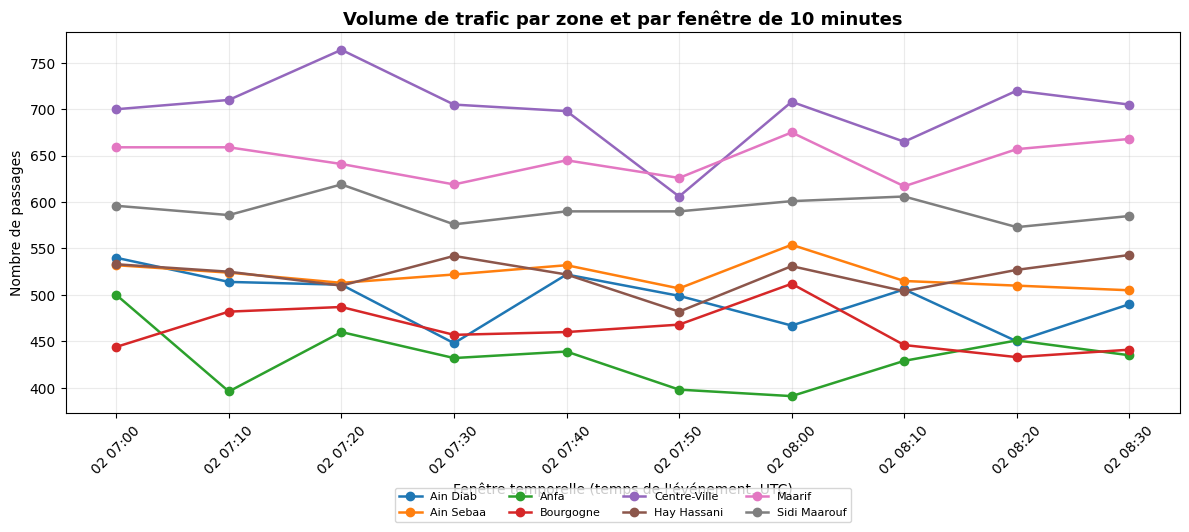

In [8]:
gold_pd = gold.toPandas()
gold_pd["window_start"] = pd.to_datetime(gold_pd["window_start"])

pivot_count = gold_pd.pivot_table(
    index="window_start", columns="zone_name", values="vehicle_count", aggfunc="sum"
).sort_index()

fig, ax = plt.subplots(figsize=(12, 5.5))
for zone in pivot_count.columns:
    ax.plot(pivot_count.index, pivot_count[zone], marker="o", linewidth=1.8, label=zone)

ax.set_title("Volume de trafic par zone et par fenêtre de 10 minutes", fontsize=13, weight="bold")
ax.set_xlabel("Fenêtre temporelle (temps de l'événement, UTC)")
ax.set_ylabel("Nombre de passages")
ax.grid(alpha=0.25)
ax.legend(ncol=4, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.18))
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
plt.show()

**Interprétation.** Les volumes sont relativement stables (environ 400 à 700 passages par
zone et par fenêtre). Les zones **Centre-Ville** et **Maarif** concentrent le plus de
trafic, ce qui est cohérent avec leur poids démographique et économique. Le pic de volume
n'est pas nécessairement le pic de congestion : la congestion dépend aussi de la vitesse.

### 7.3 Vitesse moyenne et congestion par zone

In [9]:
zone_stats = (
    gold_pd.groupby(["zone_id", "zone_name", "speed_limit_kmh"])
    .agg(vehicle_count=("vehicle_count", "sum"),
         avg_speed=("avg_speed_kmh", "mean"),
         congestion=("congestion_rate", "mean"))
    .reset_index()
    .sort_values("vehicle_count", ascending=False)
)
zone_stats["avg_speed"] = zone_stats["avg_speed"].round(1)
zone_stats["congestion"] = zone_stats["congestion"].round(3)
zone_stats

,zone_id,zone_name,speed_limit_kmh,vehicle_count,avg_speed,congestion
0,Z01,Centre-Ville,40,6981,17.5,0.857
1,Z02,Maarif,40,6466,18.7,0.825
3,Z04,Sidi Maarouf,60,5922,39.5,0.498
4,Z05,Hay Hassani,50,5219,26.2,0.760
7,Z08,Ain Sebaa,60,5214,36.4,0.618
2,Z03,Ain Diab,60,4947,37.9,0.557
6,Z07,Bourgogne,50,4630,25.2,0.781
5,Z06,Anfa,40,4331,19.3,0.812


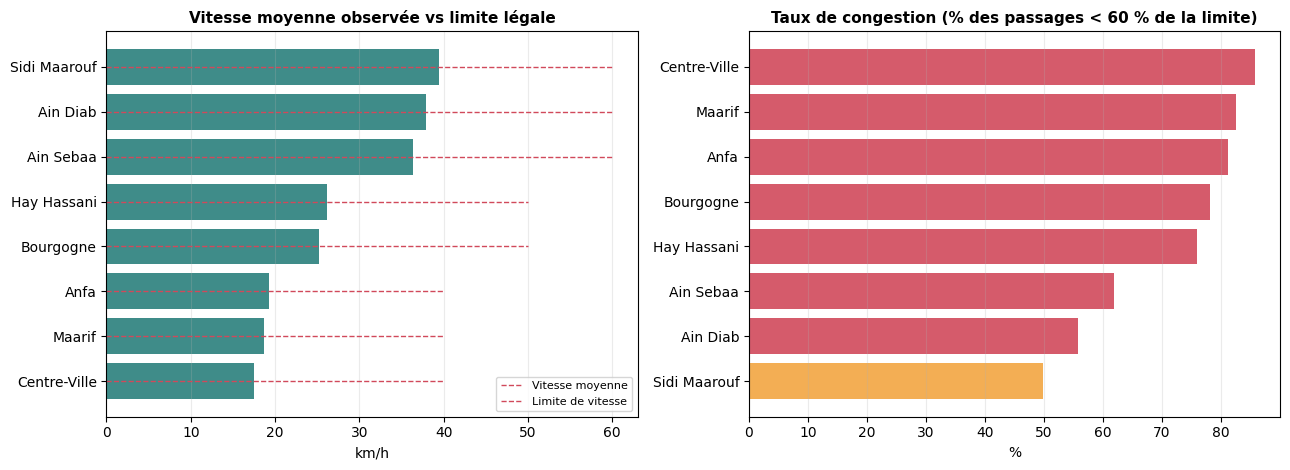

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

zs = zone_stats.sort_values("avg_speed")
axes[0].barh(zs["zone_name"], zs["avg_speed"], color="#1D7874", alpha=0.85)
for i, (_, row) in enumerate(zs.iterrows()):
    axes[0].plot([0, row["speed_limit_kmh"]], [i, i], color="#D1495B", linestyle="--", linewidth=1)
axes[0].set_title("Vitesse moyenne observée vs limite légale", fontsize=11, weight="bold")
axes[0].set_xlabel("km/h")
axes[0].grid(axis="x", alpha=0.25)
axes[0].legend(["Vitesse moyenne", "Limite de vitesse"], fontsize=8, loc="lower right")

zs2 = zone_stats.sort_values("congestion")
colors = ["#D1495B" if v > 0.5 else "#F2A541" if v > 0.3 else "#1D7874" for v in zs2["congestion"]]
axes[1].barh(zs2["zone_name"], zs2["congestion"] * 100, color=colors, alpha=0.9)
axes[1].set_title("Taux de congestion (% des passages < 60 % de la limite)", fontsize=11, weight="bold")
axes[1].set_xlabel("%")
axes[1].grid(axis="x", alpha=0.25)

fig.tight_layout()
plt.show()

**Interprétation.** Toutes les zones roulent en dessous de leur limite légale aux heures de
pointe. Les zones du centre (Centre-Ville, Maarif, Anfa) présentent les vitesses moyennes les
plus faibles et les taux de congestion les plus élevés. À l'inverse, Sidi Maarouf et Ain
Sebaâ, dotées de voies plus larges et de limites plus hautes, restent plus fluides.

### 7.4 Carte de chaleur de la congestion

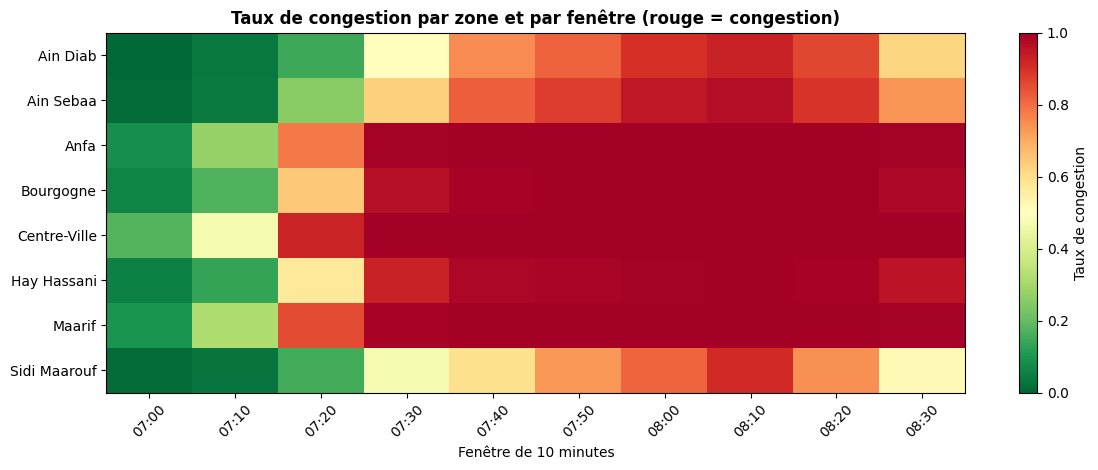

In [11]:
pivot_cong = gold_pd.pivot_table(
    index="zone_name", columns="window_start", values="congestion_rate", aggfunc="mean"
).sort_index()

fig, ax = plt.subplots(figsize=(12, 4.8))
im = ax.imshow(pivot_cong.values, aspect="auto", cmap="RdYlGn_r", vmin=0, vmax=1)
ax.set_xticks(range(len(pivot_cong.columns)))
ax.set_xticklabels([t.strftime("%H:%M") for t in pivot_cong.columns], rotation=45)
ax.set_yticks(range(len(pivot_cong.index)))
ax.set_yticklabels(pivot_cong.index)
ax.set_title("Taux de congestion par zone et par fenêtre (rouge = congestion)", fontsize=12, weight="bold")
ax.set_xlabel("Fenêtre de 10 minutes")
fig.colorbar(im, ax=ax, label="Taux de congestion")
fig.tight_layout()
plt.show()

La carte de chaleur met en évidence le **pic de 08:00–08:30**, avec des valeurs plus élevées
au centre-ville. La congestion diminue ensuite progressivement, ce qui correspond au profil
de pointe du matin simulé dans le jeu de données.

### 7.5 Fenêtres les plus critiques

In [12]:
worst = (
    gold_pd.sort_values(["congestion_rate", "vehicle_count"], ascending=False)
    .head(10)[["window_start", "zone_name", "vehicle_count", "avg_speed_kmh",
               "congestion_rate", "traffic_state"]]
)
worst["window_start"] = worst["window_start"].dt.strftime("%H:%M")
worst

,window_start,zone_name,vehicle_count,avg_speed_kmh,congestion_rate,traffic_state
4,08:00,Centre-Ville,708,13.9,1.0,Critique
5,07:40,Centre-Ville,698,15.1,1.0,Critique
53,08:00,Maarif,675,14.9,1.0,Critique
3,08:10,Centre-Ville,665,13.5,1.0,Critique
69,07:40,Maarif,645,16.1,1.0,Dense
52,07:50,Maarif,626,15.4,1.0,Critique
51,08:10,Maarif,617,14.3,1.0,Critique
2,07:50,Centre-Ville,606,14.6,1.0,Critique
60,08:00,Bourgogne,512,20.4,1.0,Dense
9,08:10,Hay Hassani,504,19.9,1.0,Critique


### 7.6 Latence des micro-batchs

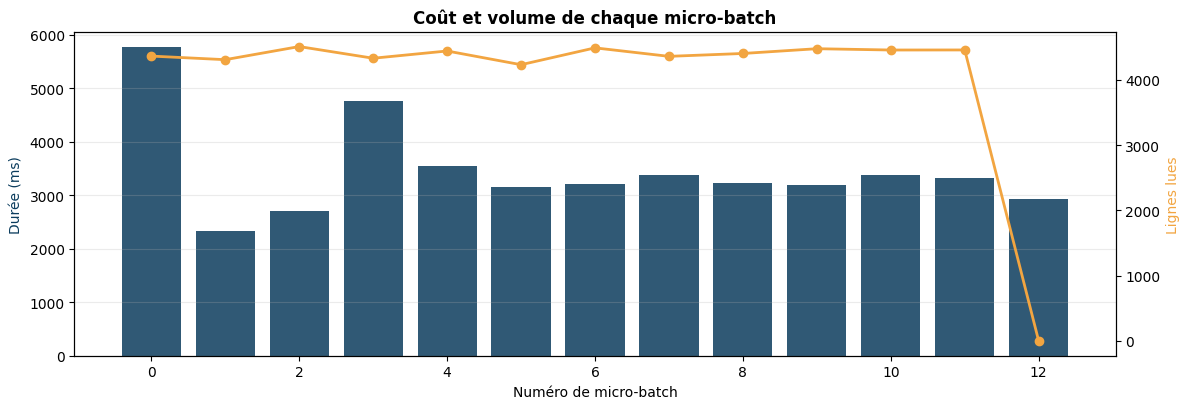

In [13]:
fig, ax1 = plt.subplots(figsize=(12, 4.2))
ax1.bar(progress["batch_id"], progress["trigger_ms"], color="#0B3C5D", alpha=0.85, label="Durée du batch")
ax1.set_xlabel("Numéro de micro-batch")
ax1.set_ylabel("Durée (ms)", color="#0B3C5D")
ax1.grid(axis="y", alpha=0.25)

ax2 = ax1.twinx()
ax2.plot(progress["batch_id"], progress["input_rows"], color="#F2A541", marker="o", linewidth=2, label="Lignes lues")
ax2.set_ylabel("Lignes lues", color="#F2A541")

ax1.set_title("Coût et volume de chaque micro-batch", fontsize=12, weight="bold")
fig.tight_layout()
plt.show()

Le coût par micro-batch reste contenu (quelques secondes), avec un premier batch plus lent
dû à l'initialisation de la JVM, de Catalyst et du State Store. Le débit est suffisant pour
un prototype local ; sur un cluster, la parallélisation et le nombre de partitions
permettraient de traiter des volumes beaucoup plus importants.

## 8. Expérience contrôlée : données tardives et watermark

Pour observer un rejet **certain**, on construit un mini-flux de quatre fichiers :

| Fichier | Événements | Rôle |
|---|---|---|
| `f1.json` | 10:05 | ouvre la fenêtre 10:00–10:10 |
| `f2.json` | 10:15 | avance le watermark |
| `f3.json` | 10:25 | ferme la fenêtre 10:00–10:10 |
| `f4.json` | 10:35 + **09:30 (très en retard)** | l'événement de 09:30 doit être ignoré |

L'événement de 09:30 appartient à une fenêtre déjà finalisée : il est rejeté et comptabilisé
dans `numRowsDroppedByWatermark`.

In [14]:
DEMO = RUNTIME / "watermark_demo"
if DEMO.exists():
    shutil.rmtree(DEMO)
DEMO.mkdir(parents=True)

def write_event(path, event_time, event_id):
    payload = {
        "event_id": event_id, "event_time": event_time, "zone_id": "Z01",
        "zone_name": "Centre-Ville", "sensor_id": "Z01-S01", "lane": 1,
        "vehicle_type": "car", "speed_kmh": 30.0,
    }
    with open(path, "a", encoding="utf-8") as fh:
        fh.write(json.dumps(payload) + "\n")

for name, ts, eid in [
    ("f1.json", "2026-11-02T10:05:00Z", "E1"),
    ("f2.json", "2026-11-02T10:15:00Z", "E2"),
    ("f3.json", "2026-11-02T10:25:00Z", "E3"),
    ("f4.json", "2026-11-02T10:35:00Z", "E4"),
]:
    write_event(DEMO / name, ts, eid)

# Événement très en retard, glissé dans le dernier fichier
write_event(DEMO / "f4.json", "2026-11-02T09:30:00Z", "E_LATE")

demo_raw = spark.readStream.schema(raw.schema).option("maxFilesPerTrigger", 1).json(str(DEMO))
demo_events = demo_raw.withColumn("event_time", F.to_timestamp("event_time")) \
                      .withWatermark("event_time", "10 minutes")
demo_agg = (
    demo_events.groupBy(F.window("event_time", "10 minutes").alias("w"))
    .agg(F.count("*").alias("n"))
    .select(F.col("w.start").alias("window_start"), F.col("w.end").alias("window_end"), "n")
)

q_demo = (
    demo_agg.writeStream.format("memory").outputMode("append")
    .queryName("watermark_demo").trigger(availableNow=True).start()
)
q_demo.awaitTermination()

print("Résultat de l'agrégation watermarkée :")
spark.sql("SELECT * FROM watermark_demo ORDER BY window_start").show(truncate=False)

demo_progress = q_demo.recentProgress
print("Événements rejetés par le watermark :",
      sum(op.get("numRowsDroppedByWatermark", 0)
          for p in demo_progress for op in (p.get("stateOperators") or [])))
print("Watermark final :", demo_progress[-1]["eventTime"].get("watermark"))

Résultat de l'agrégation watermarkée :


+-------------------+-------------------+---+
|window_start       |window_end         |n  |
+-------------------+-------------------+---+
|2026-11-02 10:00:00|2026-11-02 10:10:00|1  |
|2026-11-02 10:10:00|2026-11-02 10:20:00|1  |
+-------------------+-------------------+---+

Événements rejetés par le watermark : 1
Watermark final : 2026-11-02T10:25:00.000Z


**Résultat attendu et observé.** L'événement de 09:30 n'apparaît dans aucune fenêtre : sa
fenêtre (09:30–09:40) était déjà finalisée lorsque le fichier `f4` a été traité. La métrique
`numRowsDroppedByWatermark` vaut 1. Sans watermark, cet événement aurait créé une fenêtre
tardive et faussé les agrégats.

> **À retenir.** Le watermark est un compromis : plus il est grand, plus on accepte de
> données tardives, mais plus l'état mémoire et la latence de finalisation augmentent.

## 9. Comparaison batch / streaming

Les deux modes ont été exécutés sur **exactement le même jeu de données**. Le mode batch
calcule les 96 fenêtres en une seule passe ; le mode streaming produit les fenêtres au fil
de l'eau et en finalise 80 (les 2 dernières restant ouvertes).

In [15]:
batch_summary_path = OUTPUT / "batch_summary.json"
stream_summary_path = OUTPUT / "results_summary.json"

if batch_summary_path.exists() and stream_summary_path.exists():
    batch_summary = json.loads(batch_summary_path.read_text(encoding="utf-8"))
    stream_summary = json.loads(stream_summary_path.read_text(encoding="utf-8"))

    comparison = pd.DataFrame([
        ["Portée", "Tout le dataset (96 fenêtres)", "Micro-batch par micro-batch"],
        ["Temps de calcul", f"{batch_summary['compute_seconds']:.1f} s", f"{stream_summary['elapsed_seconds_streaming']:.1f} s au total"],
        ["Premier résultat", "Après lecture complète", f"~{stream_summary['avg_batch_duration_ms']/1000:.1f} s par micro-batch"],
        ["Fenêtres produites", batch_summary["windows"], stream_summary["finalized_windows"]],
        ["Données tardives", "Toutes intégrées", f"{stream_summary['dropped_late_events']} ignorées"],
        ["Reprise sur panne", "Relance complète", "Checkpoint / reprise exacte"],
    ], columns=["Critère", "Batch", "Streaming"])
    comparison
else:
    print("Exécutez cityflow_pipeline.py --mode available et --mode batch pour générer les synthèses.")

**Interprétation.** Le batch est plus simple et plus rapide *quand toutes les données sont
déjà disponibles*, mais il ne produit rien avant la fin de la collecte. Le streaming produit
des résultats exploitables en quelques secondes, gère les données tardives de façon explicite
et reprend sur checkpoint. Sur un volume plus important, le batch resterait pertinent pour
le rejeu historique, tandis que le streaming alimenterait le tableau de bord opérationnel.

## 10. Limites et perspectives

### Limites du prototype

- **Source fichier** : le répertoire JSON simule un flux ; il ne remplace pas un vrai broker
  (Kafka) pour la production.
- **Fichiers de petite taille** : 12 micro-lots ne permettent pas de mesurer un débit réaliste.
- **Watermark fixe** : 10 minutes est un choix arbitraire ; il faut l'adapter à la latence
  réelle du réseau de capteurs.
- **Pas de déduplication** : `event_id` n'est pas utilisé pour dédupliquer les réémissions.
- **Sink Parquet** : pas de transactions ACID ni de time travel (contrairement à Delta Lake).
- **Une seule machine** : `local[*]` ne reflète pas le comportement d'un cluster.

### Perspectives

1. Remplacer la source fichier par **Kafka** (topic `traffic-events`, plusieurs partitions).
2. Ajouter une **déduplication** par `event_id` avec watermark.
3. Écrire dans **Delta Lake** pour bénéficier d'ACID et du time travel.
4. Ajouter des **alertes** (seuil de congestion, vitesse anormale).
5. Exposer les agrégats dans un **dashboard** (Grafana, Streamlit) via un sink JDBC/Redis.
6. Passer d'un déclenchement `availableNow` à un déclenchement continu et mesurer le débit.

## Conclusion

Ce prototype démontre la mise en œuvre d'un pipeline **Structured Streaming** complet :

- ingestion d'un flux JSON avec schéma explicite ;
- nettoyage et enrichissement par jointure stream-static ;
- agrégation par zone et fenêtre temporelle sur le **temps de l'événement** ;
- gestion des données tardives par **watermark** ;
- sinks durables et checkpointés (Parquet) + sink mémoire pour l'analyse interactive ;
- réconciliation des volumes et mesure des performances par micro-batch.

Les résultats mettent en évidence le pic de congestion du matin, la prédominance du
Centre-Ville et de Maarif, et le compromis entre exhaustivité et latence introduit par le
watermark.

In [16]:
# Libération des ressources
for q in spark.streams.active:
    if q.isActive:
        q.stop()
spark.stop()
print("Session Spark arrêtée.")

Session Spark arrêtée.
